# Homework 7 · SVMs and Clustering

**Name:** Vishnu Gamini  
**GitHub Username:** vishnugamini  
**USC ID:** 6350365744  
**Course:** DSCI 552

## 1(a). Anuran Calls data

Use the 22 MFCC features to predict Family, Genus, and Species. Randomly split
rows 70/30 with species stratification and seed 42. RecordID identifies the
source recording and is excluded from the predictors. Calls from the same
recording can occur in both splits, so the results measure row-level performance.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, train_test_split
from threadpoolctl import threadpool_limits

root = Path(".") if Path("data/Frogs_MFCCs.csv").exists() else Path("..")
sys.path.insert(0, str(root / "src"))
from analysis import LABELS, cluster_trials, fit_svms, linkage_figures
from analysis import triplet_metrics

threads = threadpool_limits(limits=1)
out = root / "results"
out.mkdir(exist_ok=True)
data = pd.read_csv(root / "data/Frogs_MFCCs.csv")
X = data.filter(regex=r"^MFCCs_").to_numpy()
Y = data[LABELS]
assert X.shape == (7195, 22) and np.isfinite(X).all()
assert not Y.isna().any().any()

train, test = train_test_split(
    np.arange(len(data)), test_size=.30, random_state=42,
    stratify=Y["Species"],
)
X_train, X_test = X[train], X[test]
Y_train, Y_test = Y.iloc[train], Y.iloc[test]
folds = list(StratifiedKFold(
    n_splits=10, shuffle=True, random_state=42,
).split(X_train, Y_train["Species"]))

split = pd.Series("train", index=data.index, name="split")
split.iloc[test] = "test"
split.to_csv(out / "split.csv", index_label="row")
display(pd.Series({
    "Training rows": len(train),
    "Test rows": len(test),
    "Predictors": X.shape[1],
}))
display(Y["Species"].value_counts().rename("Rows").to_frame())

Training rows    5036
Test rows        2159
Predictors         22
dtype: int64

,Rows
Species,
AdenomeraHylaedactylus,3478
HypsiboasCordobae,1121
AdenomeraAndre,672
Ameeregatrivittata,542
HypsiboasCinerascens,472
HylaMinuta,310
LeptodactylusFuscus,270
ScinaxRuber,148
OsteocephalusOophagus,114


## 1(b)(i). Exact match and Hamming metrics

Let $d_i$ be the number of incorrect entries in row $i$'s label triplet.
Exact match is the fraction of rows with $d_i=0$. Mean Hamming distance is
$\bar d$, Hamming loss is $\bar d/3$, and Hamming score is $1-\bar d/3$.
The results also report set Jaccard, the mean of $(3-d_i)/(3+d_i)$, since
some multilabel references use “Hamming score” for this overlap measure.

## 1(b)(ii). Gaussian SVMs

Fit one model per label using one-versus-rest. Tune $C$ and
$\gamma=1/(2\sigma^2)$ by mean validation accuracy over ten stratified folds.
The grid uses $C\in\{0.1,1,10,100\}$. Raw-feature $\gamma$ values are
0.1, 0.5, 2, and 10. Standardized-feature values are 0.01, 0.05, 0.25, and 1.
The standardized pipeline fits its scaler within each training fold.

In [2]:
label_results = []
summaries = []

def evaluate(kind):
    per_label, predicted = fit_svms(
        kind, X_train, Y_train, X_test, Y_test, folds, out,
    )
    label_results.append(per_label)
    summaries.append({"model": kind, **triplet_metrics(Y_test, predicted)})
    display(per_label.drop(columns="model").round(5))

evaluate("RBF raw")
evaluate("RBF standardized")

,label,C,gamma,sigma,cv_accuracy,test_accuracy,macro_recall
0,Family,100.0,2.0,0.5,0.99265,0.99444,0.98330
1,Genus,100.0,0.5,1.0,0.98948,0.99074,0.96588
2,Species,100.0,2.0,0.5,0.98848,0.99259,0.97392


,label,C,gamma,sigma,cv_accuracy,test_accuracy,macro_recall
0,Family,100.0,0.05,3.16228,0.99325,0.99491,0.98542
1,Genus,10.0,0.05,3.16228,0.98968,0.99166,0.97047
2,Species,100.0,0.05,3.16228,0.98789,0.99027,0.97096


## 1(b)(iii). L1-penalized linear SVMs

Fit standardized one-versus-rest linear SVMs with squared hinge loss and an
L1 penalty. Choose C from 0.001, 0.01, 0.1, 1, and 10 using the same ten folds.

In [3]:
evaluate("L1 linear")

,label,C,gamma,sigma,cv_accuracy,test_accuracy,macro_recall
0,Family,0.1,NaN,NaN,0.93268,0.93979,0.69824
1,Genus,10.0,NaN,NaN,0.95274,0.94859,0.80181
2,Species,1.0,NaN,NaN,0.95731,0.96063,0.88999


## 1(b)(iv). L1 SVMs with SMOTE

For each label, standardize the training fold and apply five-neighbor SMOTE
before fitting. The validation and test rows keep their original class counts.
The final fit applies the same pipeline to the full training split.

In [4]:
evaluate("L1 SMOTE")
metrics = pd.DataFrame(summaries).set_index("model")
per_label = pd.concat(label_results, ignore_index=True)
metrics.to_csv(out / "svm_metrics.csv")
per_label.to_csv(out / "svm_per_label.csv", index=False)
display(metrics.round(5))

,label,C,gamma,sigma,cv_accuracy,test_accuracy,macro_recall
0,Family,10.0,NaN,NaN,0.91501,0.91478,0.93436
1,Genus,1.0,NaN,NaN,0.91362,0.91755,0.91496
2,Species,1.0,NaN,NaN,0.95334,0.96017,0.92406


,exact_match,hamming_distance,hamming_loss,hamming_score,set_jaccard
model,,,,,
RBF raw,0.98888,0.02223,0.00741,0.99259,0.99143
RBF standardized,0.98888,0.02316,0.00772,0.99228,0.99120
L1 linear,0.91616,0.15100,0.05033,0.94967,0.94011
L1 SMOTE,0.86105,0.20750,0.06917,0.93083,0.91158


The Gaussian SVMs both reach **98.89% exact match**.
Their Hamming losses are **0.74%** on raw features and
**0.77%** on standardized features.

SMOTE lowers exact match from **91.62%** to
**86.10%** and changes mean class recall by Family +23.61, Genus +11.32, Species +3.41
percentage points. The best exact match in this split comes from the
Gaussian models.

## 2(a). Select k and repeat 50 times

Cluster all 7,195 rows in the original MFCC space. Each trial fits k-means
once per candidate with k-means++ initialization and a distinct seed.
Select the largest Calinski–Harabasz score. The score is undefined at k=1,
so that fit is recorded and selection compares k=2 through 50. Labels are
used only after selecting k.

## 2(b). Assign cluster majority labels

Choose the most frequent Family, Genus, and Species independently within
each cluster. Break ties alphabetically.

## 2(c). Hamming distance, loss, and score

Evaluate each assigned triplet against its true triplet. Report the mean
and sample standard deviation across the 50 trials.

,mean,std
hamming_distance,0.89562,0.0
hamming_loss,0.29854,0.0
hamming_score,0.70146,0.0
exact_match,0.63614,0.0
set_jaccard,0.68189,0.0


,Trials
k,
2,50


,Family,Genus,Species,size
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3598
1,Hylidae,Hypsiboas,HypsiboasCordobae,3597


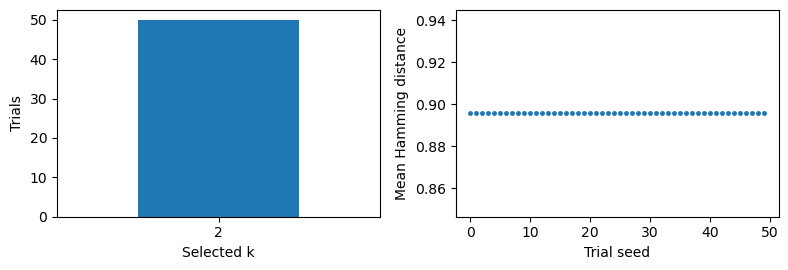

In [5]:
trials, example = cluster_trials(X, Y, out)
columns = ["hamming_distance", "hamming_loss", "hamming_score",
           "exact_match", "set_jaccard"]
summary = trials[columns].agg(["mean", "std"]).T
summary.to_csv(out / "clustering_summary.csv")
display(summary.round(5))
display(trials["k"].value_counts().sort_index().rename("Trials").to_frame())
display(example.drop(columns="seed"))
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
trials["k"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(xlabel="Selected k", ylabel="Trials")
axes[1].plot(trials["seed"], trials["hamming_distance"], ".", ms=5)
axes[1].set(xlabel="Trial seed", ylabel="Mean Hamming distance")
fig.tight_layout()
plt.show()

All 50 trials selected **k = 2** and gave the same Hamming distance to numerical precision. The mean distance was **0.89562** incorrect labels per row, corresponding to **0.29854** Hamming loss.

## 3. ISLR 12.6.2

- **(a)** Complete linkage joins {1, 2} at 0.30, then {3, 4} at 0.45.
  Their maximum cross-cluster distance is 0.80, the final merge height.
- **(b)** Single linkage joins {1, 2} at 0.30, adds 3 at 0.40, and adds 4 at
  0.45. Each merge uses the smallest distance between the two clusters.
- **(c)** Cutting the complete-linkage tree between 0.45 and 0.80 gives
  **{1, 2} and {3, 4}**.
- **(d)** Cutting the single-linkage tree between 0.40 and 0.45 gives
  **{1, 2, 3} and {4}**.
- **(e)** Reversing the two children at each complete-linkage merge reverses
  the leaf order and preserves every cluster and merge height.

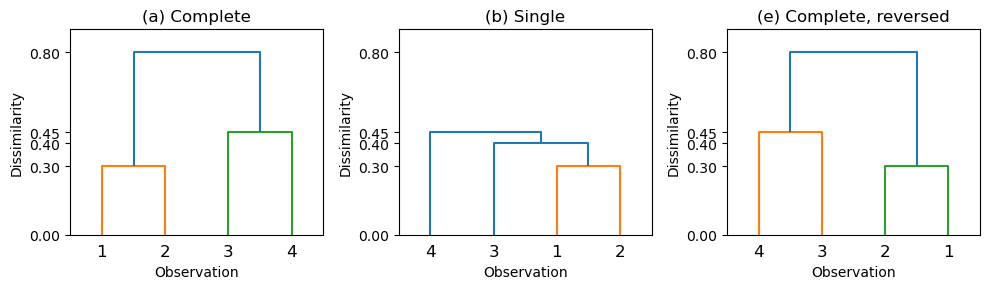

In [6]:
distances = np.array([
    [0, .30, .40, .70],
    [.30, 0, .50, .80],
    [.40, .50, 0, .45],
    [.70, .80, .45, 0],
])
complete, single, swapped = linkage_figures(distances)
assert complete[0] == complete[1] != complete[2] == complete[3]
assert single[0] == single[1] == single[2] != single[3]
assert np.array_equal(
    complete[:, None] == complete, swapped[:, None] == swapped,
)

## References

- [UCI Anuran Calls (MFCCs)](https://archive.ics.uci.edu/dataset/406/anuran+calls+mfccs)
- [Scikit-learn classification metrics](https://scikit-learn.org/1.5/modules/model_evaluation.html#classification-metrics)
- [Scikit-learn SVMs](https://scikit-learn.org/1.5/modules/svm.html)
- [SMOTE](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html)
- [Calinski–Harabasz score](https://scikit-learn.org/1.5/modules/generated/sklearn.metrics.calinski_harabasz_score.html)
- James et al., [An Introduction to Statistical Learning](https://www.statlearning.com/), 2nd ed., p. 546.

## AI disclosure

ChatGPT assisted with understanding the material, checking code, debugging,
and reviewing results.